# Where did the taxis go? Recovering fine-grained taxi pickups from zone counts

Until 2015, New York City's Taxi and Limousine Commission (TLC) published every yellow-taxi trip with
the GPS coordinates of its pickup and drop-off. From 2016 the published records give only one of
263 **taxi zones** instead. A zone is a neighbourhood-sized polygon: Midtown is four zones, Staten
Island twenty. Counts per zone hide where, inside a zone, taxis
actually stop: along an avenue, at a hotel entrance, outside a train station.

**Dasymetric disaggregation** recovers a plausible fine-grained picture. Take a year that still had
coordinates as a *prior*: it shows how pickups spread *inside* each zone. Then spread each later
zone total the same way. The totals per zone stay exactly as reported; only their placement inside the
zone comes from the prior.

With urbanweave the whole method is four calls to `match` and `aggregate`. This notebook builds it,
checks it on a month whose true locations are known, and applies it to 2016, 2019 and 2021.

*Data:* TLC yellow-taxi trip records (the 2013 FOIL release with coordinates, and the 2016+ Parquet
files with zones) and TLC's taxi zones. `prepare.py` extracts what this notebook reads; see
`README.md`.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, "../../tutorials")          # the tutorials' map and figure helpers

import numpy as np
import pandas as pd
import geopandas as gpd
import urbanweave as uw

from svgmap import Map
import diagrams
from tutorial_data import show

DATA = "data"

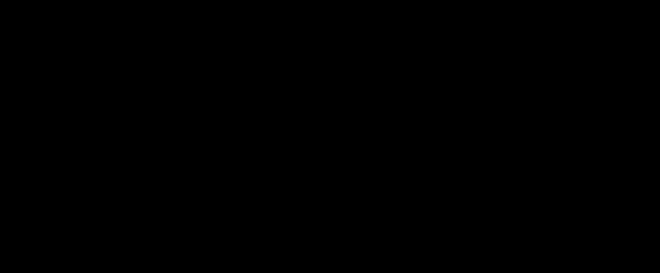

In [2]:
diagrams.dasymetric()

## The inputs

The taxi zones, a sample of 2 million pickups from January 2013 (the prior), and pickups per zone for
later months. The grid is H3 at resolution 10, cells of about 0.015 km² (a city block or two), built
over the zones themselves so that it covers the five boroughs and not the water around them.

In [3]:
zones = gpd.read_file(f"{DATA}/taxi_zones/taxi_zones/taxi_zones.shp")[["LocationID", "zone", "borough", "geometry"]]
prior = uw.points_from_columns(pd.read_parquet(f"{DATA}/pickups_2013-01.parquet"), lat="lat", lon="lon")
later = pd.read_csv(f"{DATA}/zone_counts.csv")
cells = uw.targets.h3_cells(zones, 10, cover="geometry")
print(f"{len(zones)} zones ({zones.crs.to_string()}), {len(prior):,} prior pickups, {len(cells):,} H3 cells")
later.groupby("month")["trips"].sum().map("{:,}".format)

263 zones (EPSG:2263), 2,000,000 prior pickups, 52,395 H3 cells


month
2016-07    10,294,080
2019-07     6,310,419
2021-07     2,821,746
Name: trips, dtype: str

## The method: four calls

1. Count the prior's pickups in each zone.
2. Attach each zone's later total, and the ratio *later total / prior count*.
3. Give every prior pickup its zone's ratio (`sample`: each point takes the value of the polygon it
   falls in). Each 2013 pickup now stands for that many later trips.
4. Add those weights up in each cell.

A zone with later trips but no prior pickup cannot be spread; its trips are reported, not invented.

In [4]:
def dasymetric(prior, zone_totals, zones, cells, *, zone_id="LocationID"):
    """Spread zone_totals (zone_id, trips) over cells in proportion to the prior points in each zone."""
    in_zone = uw.match(prior, zones, "contain", target_id=zone_id)                                      # 1
    per_zone = uw.aggregate(in_zone, None, [uw.count(as_="prior", fill_empty=0)])
    per_zone = per_zone.merge(zone_totals, on=zone_id, how="left").fillna({"trips": 0})              # 2 (unlisted: no trips)
    per_zone["ratio"] = per_zone["trips"] / per_zone["prior"].where(per_zone["prior"] > 0)
    weighted = uw.aggregate(uw.match(per_zone, prior, "sample", source_id=zone_id), None,              # 3
                            [uw.first("ratio", as_="weight")])
    return uw.aggregate(uw.match(weighted, cells, "contain"), None,                                     # 4
                        [uw.sum("weight", as_="trips", fill_empty=0)]), per_zone

## Does it work? A month with known answers

2013 has coordinates for every month, so the method can be tested honestly. Take **July 2013**: count
its pickups per zone (what a later year would publish), rebuild the cells from those counts with the
January prior, and compare with the true July pickups per cell. Six months apart, the season and the
mix of trips differ, so this is a fair test.

The baseline is plain **areal weighting**, what one would do without a prior: each zone's total is
spread in proportion to area (`area_overlap` from zones to cells).

In [5]:
july = uw.points_from_columns(pd.read_parquet(f"{DATA}/pickups_2013-07.parquet"), lat="lat", lon="lon")

truth = uw.aggregate(uw.match(july, cells, "contain"), None, [uw.count(as_="trips", fill_empty=0)])
july_zones = uw.aggregate(uw.match(july, zones, "contain", target_id="LocationID"), None,
                          [uw.count(as_="trips", fill_empty=0)])[["LocationID", "trips"]]

estimate, _ = dasymetric(prior, july_zones, zones, cells)
areal = uw.aggregate(uw.match(zones.merge(july_zones, on="LocationID"), cells, "area_overlap", source_id="LocationID"),
                     None, [uw.sum("trips", as_="trips", fill_empty=0)])

In [6]:
def compare(estimate, truth):
    t = truth.set_index("target_id")["trips"].astype(float)
    e = estimate.set_index("target_id")["trips"].astype(float).reindex(t.index).fillna(0)
    busy = t >= t.quantile(0.99)
    return {"trips placed": round(e.sum()),
            "share in the wrong cell": f"{(t - e).abs().sum() / t.sum() / 2:.1%}",
            "correlation with truth": round(np.corrcoef(t, e)[0, 1], 3),
            "error in the busiest 1% of cells": f"{(t - e)[busy].abs().sum() / t[busy].sum():.1%}"}

pd.DataFrame({"truth": {"trips placed": int(truth["trips"].sum())},
              "dasymetric (January prior)": compare(estimate, truth),
              "areal weighting": compare(areal, truth)})

,truth,dasymetric (January prior),areal weighting
trips placed,1995855.0,1995930,1973564
share in the wrong cell,NaN,5.1%,35.8%
correlation with truth,NaN,0.995,0.736
error in the busiest 1% of cells,NaN,6.7%,48.3%


Areal weighting puts about a third of the trips in the wrong cells: it spreads a zone's pickups
evenly over parks, rail yards and quiet side streets. The dasymetric estimate gets all but a few
percent right, from zone counts alone. The maps zoom into Midtown Manhattan, where taxis cluster
most, at full resolution.

In [7]:
from shapely.geometry import box
midtown = gpd.GeoDataFrame({"target_id": ["Midtown"]}, geometry=[box(-74.005, 40.740, -73.962, 40.772)], crs=4326)
midtown_cells = set(uw.match(cells, midtown, "centroid").pairs["source_id"])   # cells whose centre is in the box
manhattan = zones[zones["borough"] == "Manhattan"]
BINS = [0, 100, 300, 600, 1000, 1500, 2500, 16000]   # about the quantiles of the truth in Midtown

def midtown_map(frame, title):
    return (Map(title, width=440, crs=32618)
            .fill(frame[frame["target_id"].isin(midtown_cells)], "trips", bounds=BINS,
                  legend="pickups per cell, July 2013 sample", tooltip=["target_id"])
            .outline(manhattan.clip(midtown.to_crs(manhattan.crs)), width=0.8))

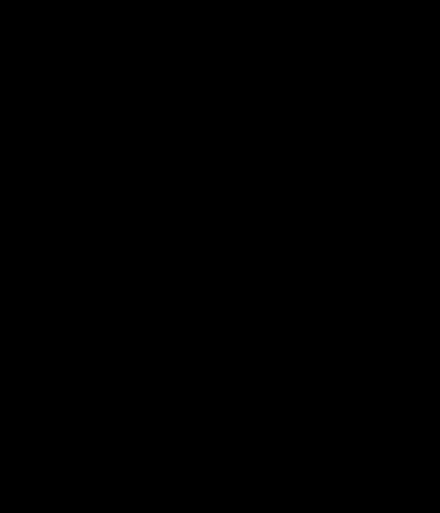

In [8]:
midtown_map(truth, "Truth: July 2013 pickups, Midtown")

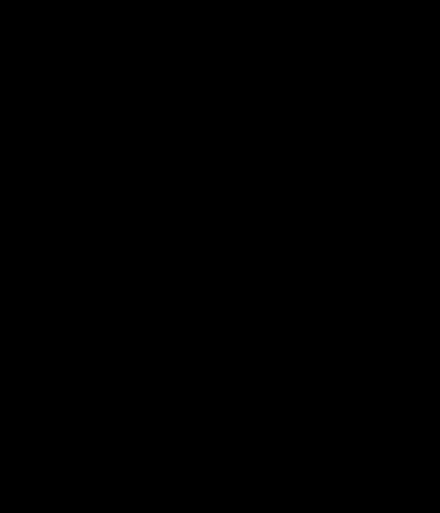

In [9]:
midtown_map(estimate, "Dasymetric: rebuilt from zone counts")

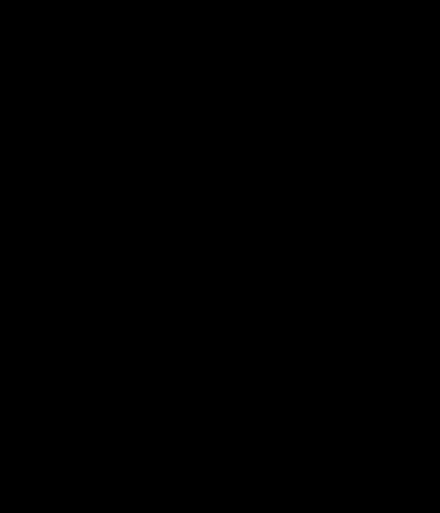

In [10]:
midtown_map(areal, "Areal weighting: rebuilt from zone counts")

Areal weighting paints each zone a nearly flat colour, blind to where inside the zone taxis stop; the
dasymetric estimate keeps the pattern of the avenues and the busiest blocks. The few hatched cells
(28 in the city, mostly on the waterfront) hold only 2013 pickups that fall outside every taxi zone:
there is no zone total to spread there, so they stay missing rather than zero.

## What the reports say

Nothing is dropped silently. Some 2013 pickups fall outside every zone (in the rivers, or across the
Hudson in New Jersey), and some cells lie partly outside the zones, so areal weighting leaves part
of a zone's area unallocated. The reports count both.

In [11]:
show(uw.report_of(july_zones)["match"]["sources"]["unmatched"])
show(uw.report_of(areal)["aggregate"][0]["extensive"])

{
 "no_target": {
  "count": 2357,
  "sample": [3551, 4762, 5645, 6296, 7584, 10599, 11338, 11965, 11997, 12322]
 }
}
{
 "valid_input": 1997643.0,
 "matched_input": 1997643.0,
 "unmatched_input": 0.0,
 "allocated": 1973563.5545320874,
 "unallocated": 24079.445467912592
}


## Applying it: July 2016, 2019 and 2021

The later months have zone counts only. Their totals are spread with the January 2013 prior. Each
zone's total is kept exactly; zone IDs 264 and 265 ("unknown" in TLC's records) have no polygon,
and zones whose total has no prior pickups to follow are reported.

In [12]:
results = {}
for month, counts in later.groupby("month"):
    est, per_zone = dasymetric(prior, counts[["LocationID", "trips"]], zones, cells)
    results[month] = est
    unplaced = counts.loc[~counts["LocationID"].isin(per_zone.loc[per_zone["prior"] > 0, "LocationID"]), "trips"].sum()
    print(f"{month}: {counts['trips'].sum():>10,} trips reported, {est['trips'].sum():>12,.0f} placed in cells, "
          f"{unplaced:>7,} in zones without a polygon or a prior")

2016-07: 10,294,080 trips reported,   10,146,427 placed in cells, 138,679 in zones without a polygon or a prior


2019-07:  6,310,419 trips reported,    6,251,266 placed in cells,  53,789 in zones without a polygon or a prior


2021-07:  2,821,746 trips reported,    2,788,318 placed in cells,  31,321 in zones without a polygon or a prior


For a whole-borough view, the resolution-10 estimates move up to resolution 9 (cells of about
0.1 km²) with one more step: each fine cell goes to the coarser cell containing its centre, and the
trips add up. Steps chain: the output of one is the source of the next.

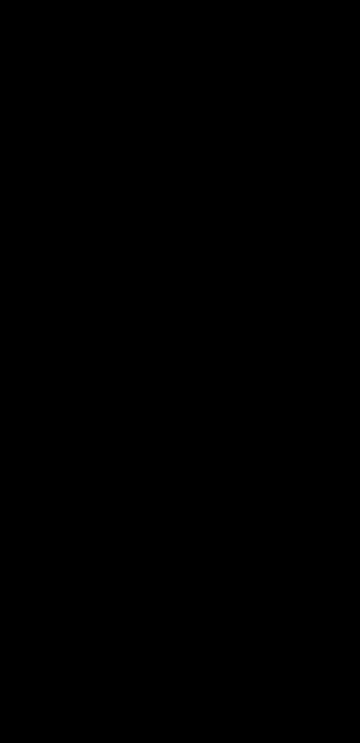

In [13]:
cells9 = uw.targets.h3_cells(manhattan, 9, cover="geometry")
BINS_MONTH = [0, 2000, 5000, 10000, 20000, 40000, 80000, 400000]

def month_map(month):
    coarse = uw.aggregate(uw.match(results[month], cells9, "centroid"), None, [uw.sum("trips", as_="trips", fill_empty=0)])
    return (Map(f"Yellow-taxi pickups in Manhattan, {month}", width=360, crs=32618)
            .fill(coarse, "trips", bounds=BINS_MONTH, legend="estimated pickups per cell, whole month")
            .outline(manhattan, width=0.5))

month_map("2016-07")

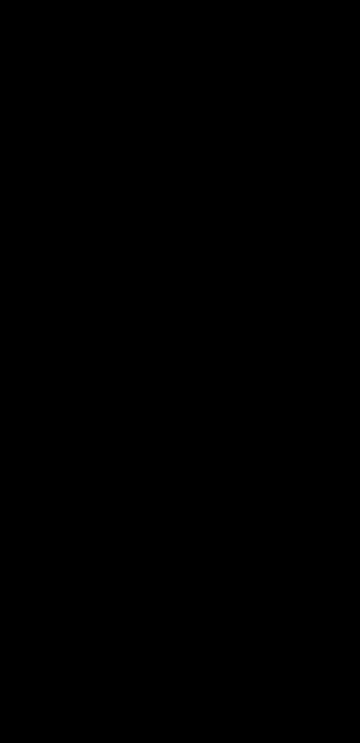

In [14]:
month_map("2019-07")

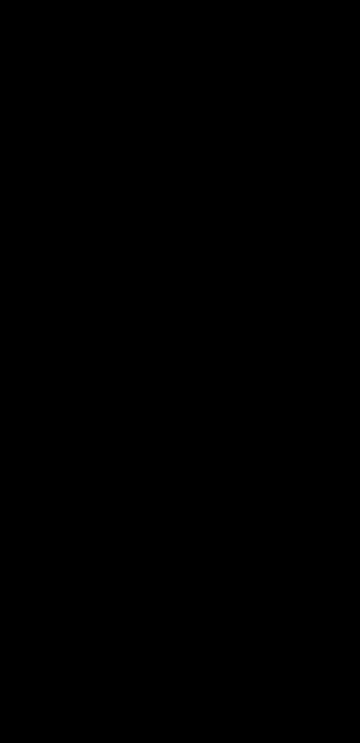

In [15]:
month_map("2021-07")

Between 2016 and 2021 yellow-taxi pickups fell by almost three quarters, first as ride-hail
services grew and then with the pandemic. The maps show where the remaining trips are: still Midtown and
the avenues, at a fraction of the volume.

## What the estimate can and cannot say

- **Totals are data, placement is model.** Each zone's monthly total is exactly what TLC reported.
  Its distribution inside the zone is the 2013 pattern; a new hotel or a closed station within a zone
  is invisible.
- **The prior matters.** A prior from the same season, or several months pooled, will fit better than
  one January. The July 2013 test above measures how much a six-month gap costs.
- **Fine cells need many points.** At resolution 10 a 2-million-trip sample gives Manhattan cells
  hundreds of pickups each, but outer-borough cells only a handful, so their estimates are noisier.
- **Drop-offs work the same way**, with the drop-off coordinates as the prior and `DOLocationID` as
  the zones.

The same four calls work for any count published by zone (bike-share trips by station area, 311
calls by community district) whenever an earlier or related dataset shows where things happen
inside the zones.